Lab 5

In [116]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import h5py

In [117]:
#hf = h5py.File('Shared/H-H1_GWOSC_4KHZ_R1-1253883712-4096.hdf5', 'r')

In [118]:
#hf.keys()

In [119]:
#data1 = np.array(hf.get('meta'))
#data2 = np.array(hf.get('quality'))
#data3 = np.array(hf.get('strain'))

In [120]:
#print(np.shape(data1))
#print(np.shape(data2))
#print(np.shape(data3))

In [121]:
t0 = 1177008882.4
detector = 'H1'

In [122]:
try:
    from gwpy.timeseries import TimeSeries
except:
    ! pip install -q "gwpy==3.0.13"
    from gwpy.timeseries import TimeSeries

In [123]:
center = int(t0)  #-- Round GPS time to nearest second
strain = TimeSeries.fetch_open_data(detector, center-16, center+16)
print(strain)

TimeSeries([4.90370064e-19, 4.81179811e-19, 4.68211191e-19, ...,
            5.22817961e-19, 5.30514245e-19, 5.34618547e-19]
           unit: dimensionless,
           t0: 1177008866.0 s,
           dt: 0.000244140625 s,
           name: Strain,
           channel: None)


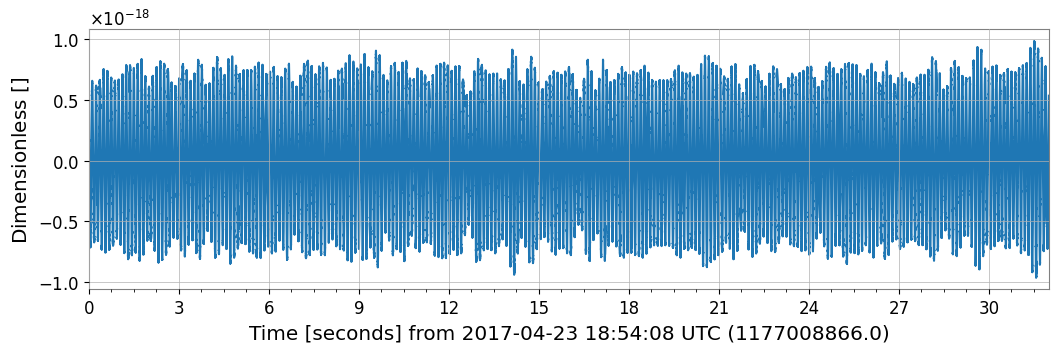

In [124]:
fig1 = strain.plot()

(1e-24, 1e-19)

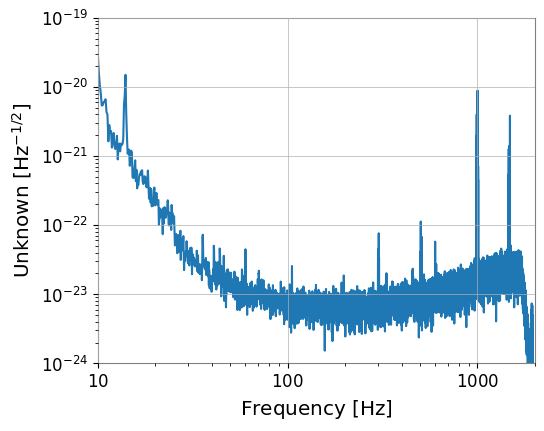

In [125]:
fig2 = strain.asd(fftlength=8).plot()
plt.xlim(10,2000)
plt.ylim(1e-24, 1e-19)

(1177008882.2, 1177008882.5)

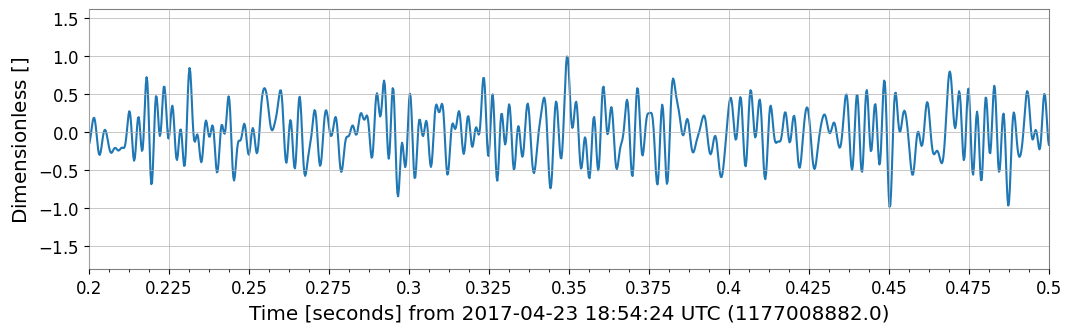

In [126]:
white_data = strain.whiten()
bp_data = white_data.bandpass(30, 400)
fig3 = bp_data.plot()
plt.xlim(t0-0.2, t0+0.1)

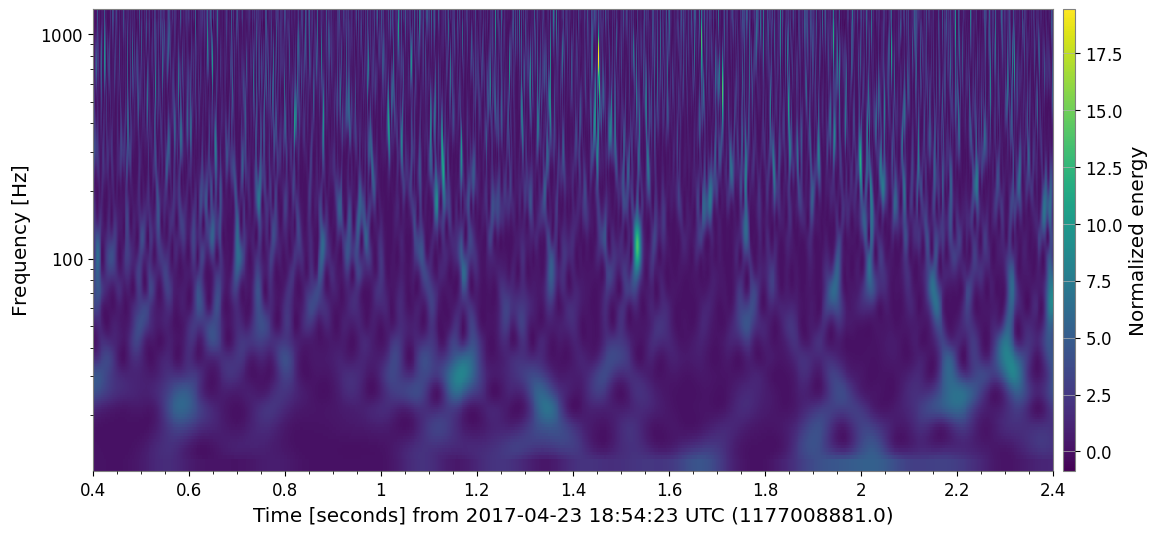

In [127]:
dt = 1  #-- Set width of q-transform plot, in seconds
hq = strain.q_transform(outseg=(t0-dt, t0+dt))
fig4 = hq.plot()
ax = fig4.gca()
ax.grid(False)
ax.set_yscale('log')
try: fig4.colorbar(label="Normalized energy")
except: pass

 My written project is about gravational waves. For gravational waves there are normally 4 related experimental quantities, which is time, frequency,energy,strain(which is changing length of a quantity divided by original quantity). And based on those quantities, we choose to graph can graph time strain vs time, frequency strain vs frequency and a 3d histogram of frequency vs normalized energy vs time. My proposal is how can we tell from data that one obervation can considered to be significant, and what that significant event correponds to? For example, is it a gravational wave, or something else? My plan is to create a background noise graph for each 4 plot. then model them with a distribution. Then I will map "anomaly" "significant event" to Gravitational wave or other cosmic event. The main "significant event" we are mapping is still gravitational wave.